# NF-CSE-CIC-IDS2018v2: Dataset Exploration

## Objective
Understand the dataset before preprocessing or modeling.

## Questions
1. What does one row represent?
2. How many observations and features are present?
3. What are the column names and data types?
4. Which column contains the target label?
5. Which attack classes are represented?
6. Is the dataset imbalanced?
7. Are there missing or infinite values?
8. Are duplicate rows present?
9. Is there meaningful temporal information?


In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

In [2]:
df = pd.read_parquet("../data/raw/NF-CSE-CIC-IDS2018-V2.parquet")

In [3]:
df.head()

,L4_SRC_PORT,L4_DST_PORT,PROTOCOL,L7_PROTO,IN_BYTES,IN_PKTS,OUT_BYTES,OUT_PKTS,TCP_FLAGS,CLIENT_TCP_FLAGS,...,TCP_WIN_MAX_IN,TCP_WIN_MAX_OUT,ICMP_TYPE,ICMP_IPV4_TYPE,DNS_QUERY_ID,DNS_QUERY_TYPE,DNS_TTL_ANSWER,FTP_COMMAND_RET_CODE,Label,Attack
0,40894,22,6,92.0,3164,23,3765,21,27,27,...,26883,26847,0,0,0,0,0,0,1,SSH-Bruteforce
1,29622,3389,6,0.0,1919,14,2031,11,223,219,...,8192,64000,0,0,0,0,0,0,0,Benign
2,65456,53,17,0.0,116,2,148,2,0,0,...,0,0,0,0,2511,1,5,0,0,Benign
3,57918,53,17,0.0,70,1,130,1,0,0,...,0,0,0,0,3371,1,60,0,0,Benign
4,63269,80,6,7.0,232,5,1136,4,223,222,...,8192,26883,0,0,0,0,0,0,1,DDoS attacks-LOIC-HTTP


In [4]:
df.shape

(17129715, 43)

In [5]:
df.columns.tolist()

['L4_SRC_PORT',
 'L4_DST_PORT',
 'PROTOCOL',
 'L7_PROTO',
 'IN_BYTES',
 'IN_PKTS',
 'OUT_BYTES',
 'OUT_PKTS',
 'TCP_FLAGS',
 'CLIENT_TCP_FLAGS',
 'SERVER_TCP_FLAGS',
 'FLOW_DURATION_MILLISECONDS',
 'DURATION_IN',
 'DURATION_OUT',
 'MIN_TTL',
 'MAX_TTL',
 'LONGEST_FLOW_PKT',
 'SHORTEST_FLOW_PKT',
 'MIN_IP_PKT_LEN',
 'MAX_IP_PKT_LEN',
 'SRC_TO_DST_SECOND_BYTES',
 'DST_TO_SRC_SECOND_BYTES',
 'RETRANSMITTED_IN_BYTES',
 'RETRANSMITTED_IN_PKTS',
 'RETRANSMITTED_OUT_BYTES',
 'RETRANSMITTED_OUT_PKTS',
 'SRC_TO_DST_AVG_THROUGHPUT',
 'DST_TO_SRC_AVG_THROUGHPUT',
 'NUM_PKTS_UP_TO_128_BYTES',
 'NUM_PKTS_128_TO_256_BYTES',
 'NUM_PKTS_256_TO_512_BYTES',
 'NUM_PKTS_512_TO_1024_BYTES',
 'NUM_PKTS_1024_TO_1514_BYTES',
 'TCP_WIN_MAX_IN',
 'TCP_WIN_MAX_OUT',
 'ICMP_TYPE',
 'ICMP_IPV4_TYPE',
 'DNS_QUERY_ID',
 'DNS_QUERY_TYPE',
 'DNS_TTL_ANSWER',
 'FTP_COMMAND_RET_CODE',
 'Label',
 'Attack']

In [6]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 17129715 entries, 0 to 17129714
Data columns (total 43 columns):
 #   Column                       Dtype  
---  ------                       -----  
 0   L4_SRC_PORT                  int32  
 1   L4_DST_PORT                  int32  
 2   PROTOCOL                     int8   
 3   L7_PROTO                     float32
 4   IN_BYTES                     int32  
 5   IN_PKTS                      int32  
 6   OUT_BYTES                    int32  
 7   OUT_PKTS                     int32  
 8   TCP_FLAGS                    int16  
 9   CLIENT_TCP_FLAGS             int16  
 10  SERVER_TCP_FLAGS             int16  
 11  FLOW_DURATION_MILLISECONDS   int32  
 12  DURATION_IN                  int32  
 13  DURATION_OUT                 int32  
 14  MIN_TTL                      int16  
 15  MAX_TTL                      int16  
 16  LONGEST_FLOW_PKT             int32  
 17  SHORTEST_FLOW_PKT            int16  
 18  MIN_IP_PKT_LEN               int16  
 19  MAX_IP_PK

In [7]:
df["Attack"].value_counts()

Attack
Benign                      15101685
DDOS attack-HOIC             1066881
DoS attacks-Hulk              432648
DDoS attacks-LOIC-HTTP        207078
Infilteration                 115513
SSH-Bruteforce                 94979
Bot                            28033
DoS attacks-GoldenEye          27723
FTP-BruteForce                 25933
DoS attacks-SlowHTTPTest       14116
DoS attacks-Slowloris           9512
Brute Force -Web                2143
DDOS attack-LOIC-UDP            2112
Brute Force -XSS                 927
SQL Injection                    432
Name: count, dtype: int64

In [8]:
df["Label"].value_counts()

Label
0    15101685
1     2028030
Name: count, dtype: int64

In [9]:
df[["Label", "Attack"]].value_counts()

Label  Attack                  
0      Benign                      15101685
1      DDOS attack-HOIC             1066881
       DoS attacks-Hulk              432648
       DDoS attacks-LOIC-HTTP        207078
       Infilteration                 115513
       SSH-Bruteforce                 94979
       Bot                            28033
       DoS attacks-GoldenEye          27723
       FTP-BruteForce                 25933
       DoS attacks-SlowHTTPTest       14116
       DoS attacks-Slowloris           9512
       Brute Force -Web                2143
       DDOS attack-LOIC-UDP            2112
       Brute Force -XSS                 927
       SQL Injection                    432
Name: count, dtype: int64

In [10]:
df["Attack"].value_counts(normalize=True) * 100

Attack
Benign                      88.160749
DDOS attack-HOIC             6.228247
DoS attacks-Hulk             2.525716
DDoS attacks-LOIC-HTTP       1.208882
Infilteration                0.674343
SSH-Bruteforce               0.554469
Bot                          0.163651
DoS attacks-GoldenEye        0.161842
FTP-BruteForce               0.151392
DoS attacks-SlowHTTPTest     0.082407
DoS attacks-Slowloris        0.055529
Brute Force -Web             0.012510
DDOS attack-LOIC-UDP         0.012329
Brute Force -XSS             0.005412
SQL Injection                0.002522
Name: proportion, dtype: float64

In [11]:
df["Attack"].nunique()

15

In [12]:
df["Attack"].value_counts().tail(5)

Attack
DoS attacks-Slowloris    9512
Brute Force -Web         2143
DDOS attack-LOIC-UDP     2112
Brute Force -XSS          927
SQL Injection             432
Name: count, dtype: int64

In [13]:
df["Attack"] == "Benign"

0           False
1            True
2            True
3            True
4           False
            ...  
17129710     True
17129711     True
17129712    False
17129713     True
17129714     True
Name: Attack, Length: 17129715, dtype: bool

In [14]:
df.loc[df["Attack"] == "Benign", "Label"]

1           0
2           0
3           0
5           0
6           0
           ..
17129709    0
17129710    0
17129711    0
17129713    0
17129714    0
Name: Label, Length: 15101685, dtype: int8

In [15]:
df.loc[df["Attack"] == "Benign", "Label"].unique()

array([0], dtype=int8)

In [16]:
df.loc[df["Attack"] != "Benign", "Label"].unique()

array([1], dtype=int8)

## Observation
### Label is consistent across attack, it is 0 for benign and 1 for any kind of attack, this makes binary classification possible 

In [17]:
df.isna().sum()

L4_SRC_PORT                    0
L4_DST_PORT                    0
PROTOCOL                       0
L7_PROTO                       0
IN_BYTES                       0
IN_PKTS                        0
OUT_BYTES                      0
OUT_PKTS                       0
TCP_FLAGS                      0
CLIENT_TCP_FLAGS               0
SERVER_TCP_FLAGS               0
FLOW_DURATION_MILLISECONDS     0
DURATION_IN                    0
DURATION_OUT                   0
MIN_TTL                        0
MAX_TTL                        0
LONGEST_FLOW_PKT               0
SHORTEST_FLOW_PKT              0
MIN_IP_PKT_LEN                 0
MAX_IP_PKT_LEN                 0
SRC_TO_DST_SECOND_BYTES        0
DST_TO_SRC_SECOND_BYTES        0
RETRANSMITTED_IN_BYTES         0
RETRANSMITTED_IN_PKTS          0
RETRANSMITTED_OUT_BYTES        0
RETRANSMITTED_OUT_PKTS         0
SRC_TO_DST_AVG_THROUGHPUT      0
DST_TO_SRC_AVG_THROUGHPUT      0
NUM_PKTS_UP_TO_128_BYTES       0
NUM_PKTS_128_TO_256_BYTES      0
NUM_PKTS_2

### There are no missing values across all 12 columns

In [18]:
df.select_dtypes(include= "number")

,L4_SRC_PORT,L4_DST_PORT,PROTOCOL,L7_PROTO,IN_BYTES,IN_PKTS,OUT_BYTES,OUT_PKTS,TCP_FLAGS,CLIENT_TCP_FLAGS,...,NUM_PKTS_1024_TO_1514_BYTES,TCP_WIN_MAX_IN,TCP_WIN_MAX_OUT,ICMP_TYPE,ICMP_IPV4_TYPE,DNS_QUERY_ID,DNS_QUERY_TYPE,DNS_TTL_ANSWER,FTP_COMMAND_RET_CODE,Label
0,40894,22,6,92.000000,3164,23,3765,21,27,27,...,1,26883,26847,0,0,0,0,0,0,1
1,29622,3389,6,0.000000,1919,14,2031,11,223,219,...,1,8192,64000,0,0,0,0,0,0,0
2,65456,53,17,0.000000,116,2,148,2,0,0,...,0,0,0,0,0,2511,1,5,0,0
3,57918,53,17,0.000000,70,1,130,1,0,0,...,0,0,0,0,0,3371,1,60,0,0
4,63269,80,6,7.000000,232,5,1136,4,223,222,...,0,8192,26883,0,0,0,0,0,0,1
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
17129710,59578,53,17,0.000000,77,1,138,1,0,0,...,0,0,0,0,0,14428,1,60,0,0
17129711,52954,443,6,91.220001,1729,20,6719,16,27,27,...,3,8192,29200,0,0,0,0,0,0,0
17129712,59664,80,6,7.000000,561,5,1147,5,219,219,...,0,65535,26883,0,0,0,0,0,0,1
17129713,1780,445,6,41.000000,120,3,124,3,23,19,...,0,65392,65392,0,0,0,0,0,0,0


In [19]:
df.select_dtypes(include="number").columns

Index(['L4_SRC_PORT', 'L4_DST_PORT', 'PROTOCOL', 'L7_PROTO', 'IN_BYTES',
       'IN_PKTS', 'OUT_BYTES', 'OUT_PKTS', 'TCP_FLAGS', 'CLIENT_TCP_FLAGS',
       'SERVER_TCP_FLAGS', 'FLOW_DURATION_MILLISECONDS', 'DURATION_IN',
       'DURATION_OUT', 'MIN_TTL', 'MAX_TTL', 'LONGEST_FLOW_PKT',
       'SHORTEST_FLOW_PKT', 'MIN_IP_PKT_LEN', 'MAX_IP_PKT_LEN',
       'SRC_TO_DST_SECOND_BYTES', 'DST_TO_SRC_SECOND_BYTES',
       'RETRANSMITTED_IN_BYTES', 'RETRANSMITTED_IN_PKTS',
       'RETRANSMITTED_OUT_BYTES', 'RETRANSMITTED_OUT_PKTS',
       'SRC_TO_DST_AVG_THROUGHPUT', 'DST_TO_SRC_AVG_THROUGHPUT',
       'NUM_PKTS_UP_TO_128_BYTES', 'NUM_PKTS_128_TO_256_BYTES',
       'NUM_PKTS_256_TO_512_BYTES', 'NUM_PKTS_512_TO_1024_BYTES',
       'NUM_PKTS_1024_TO_1514_BYTES', 'TCP_WIN_MAX_IN', 'TCP_WIN_MAX_OUT',
       'ICMP_TYPE', 'ICMP_IPV4_TYPE', 'DNS_QUERY_ID', 'DNS_QUERY_TYPE',
       'DNS_TTL_ANSWER', 'FTP_COMMAND_RET_CODE', 'Label'],
      dtype='str')

In [20]:
df.columns

Index(['L4_SRC_PORT', 'L4_DST_PORT', 'PROTOCOL', 'L7_PROTO', 'IN_BYTES',
       'IN_PKTS', 'OUT_BYTES', 'OUT_PKTS', 'TCP_FLAGS', 'CLIENT_TCP_FLAGS',
       'SERVER_TCP_FLAGS', 'FLOW_DURATION_MILLISECONDS', 'DURATION_IN',
       'DURATION_OUT', 'MIN_TTL', 'MAX_TTL', 'LONGEST_FLOW_PKT',
       'SHORTEST_FLOW_PKT', 'MIN_IP_PKT_LEN', 'MAX_IP_PKT_LEN',
       'SRC_TO_DST_SECOND_BYTES', 'DST_TO_SRC_SECOND_BYTES',
       'RETRANSMITTED_IN_BYTES', 'RETRANSMITTED_IN_PKTS',
       'RETRANSMITTED_OUT_BYTES', 'RETRANSMITTED_OUT_PKTS',
       'SRC_TO_DST_AVG_THROUGHPUT', 'DST_TO_SRC_AVG_THROUGHPUT',
       'NUM_PKTS_UP_TO_128_BYTES', 'NUM_PKTS_128_TO_256_BYTES',
       'NUM_PKTS_256_TO_512_BYTES', 'NUM_PKTS_512_TO_1024_BYTES',
       'NUM_PKTS_1024_TO_1514_BYTES', 'TCP_WIN_MAX_IN', 'TCP_WIN_MAX_OUT',
       'ICMP_TYPE', 'ICMP_IPV4_TYPE', 'DNS_QUERY_ID', 'DNS_QUERY_TYPE',
       'DNS_TTL_ANSWER', 'FTP_COMMAND_RET_CODE', 'Label', 'Attack'],
      dtype='str')

In [21]:
np.isinf(df.select_dtypes(include="number")).sum()

L4_SRC_PORT                    0
L4_DST_PORT                    0
PROTOCOL                       0
L7_PROTO                       0
IN_BYTES                       0
IN_PKTS                        0
OUT_BYTES                      0
OUT_PKTS                       0
TCP_FLAGS                      0
CLIENT_TCP_FLAGS               0
SERVER_TCP_FLAGS               0
FLOW_DURATION_MILLISECONDS     0
DURATION_IN                    0
DURATION_OUT                   0
MIN_TTL                        0
MAX_TTL                        0
LONGEST_FLOW_PKT               0
SHORTEST_FLOW_PKT              0
MIN_IP_PKT_LEN                 0
MAX_IP_PKT_LEN                 0
SRC_TO_DST_SECOND_BYTES        0
DST_TO_SRC_SECOND_BYTES        0
RETRANSMITTED_IN_BYTES         0
RETRANSMITTED_IN_PKTS          0
RETRANSMITTED_OUT_BYTES        0
RETRANSMITTED_OUT_PKTS         0
SRC_TO_DST_AVG_THROUGHPUT      0
DST_TO_SRC_AVG_THROUGHPUT      0
NUM_PKTS_UP_TO_128_BYTES       0
NUM_PKTS_128_TO_256_BYTES      0
NUM_PKTS_2

### No column contains infinity values

In [22]:
df.duplicated().sum()

np.int64(0)

### No exact duplicate rows

In [23]:
df.select_dtypes(include = "number").describe()

/home/krix/Network-Packet-Anomaly-Detector/.venv/lib64/python3.14/site-packages/pandas/core/nanops.py:1028: RuntimeWarning: overflow encountered in square
  sqr = _ensure_numeric((avg - values) ** 2)


,L4_SRC_PORT,L4_DST_PORT,PROTOCOL,L7_PROTO,IN_BYTES,IN_PKTS,OUT_BYTES,OUT_PKTS,TCP_FLAGS,CLIENT_TCP_FLAGS,...,NUM_PKTS_1024_TO_1514_BYTES,TCP_WIN_MAX_IN,TCP_WIN_MAX_OUT,ICMP_TYPE,ICMP_IPV4_TYPE,DNS_QUERY_ID,DNS_QUERY_TYPE,DNS_TTL_ANSWER,FTP_COMMAND_RET_CODE,Label
count,1.712972e+07,1.712972e+07,1.712972e+07,1.712972e+07,1.712972e+07,1.712972e+07,1.712972e+07,1.712972e+07,1.712972e+07,1.712972e+07,...,1.712972e+07,1.712972e+07,1.712972e+07,1.712972e+07,1.712972e+07,1.712972e+07,1.712972e+07,1.712972e+07,17129715.0,1.712972e+07
mean,5.294724e+04,1.094130e+03,1.099481e+01,1.124135e+01,1.950476e+03,2.516168e+01,7.548850e+03,1.029305e+01,7.313998e+01,7.245994e+01,...,4.621476e+00,1.161440e+04,2.099478e+04,3.295023e+03,1.287118e+01,1.475715e+04,4.290153e+00,2.112908e+01,0.0,1.183925e-01
std,1.152073e+04,3.297370e+03,5.488639e+00,2.690619e+01,8.362588e+04,1.147684e+03,5.221193e+05,3.527853e+02,9.812362e+01,9.790705e+01,...,3.487432e+02,1.950126e+04,2.541743e+04,1.213021e+04,4.738362e+01,2.066545e+04,1.628592e+01,4.222626e+01,0.0,3.230723e-01
min,0.000000e+00,0.000000e+00,1.000000e+00,0.000000e+00,2.800000e+01,1.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,...,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,0.0,0.000000e+00
25%,5.090300e+04,5.300000e+01,6.000000e+00,0.000000e+00,6.900000e+01,1.000000e+00,1.190000e+02,1.000000e+00,0.000000e+00,0.000000e+00,...,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,0.0,0.000000e+00
50%,5.459100e+04,8.000000e+01,6.000000e+00,0.000000e+00,1.440000e+02,3.000000e+00,2.940000e+02,3.000000e+00,2.300000e+01,1.900000e+01,...,0.000000e+00,8.192000e+03,8.192000e+03,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,0.0,0.000000e+00
75%,5.979300e+04,4.450000e+02,1.700000e+01,7.000000e+00,1.464000e+03,9.000000e+00,1.873000e+03,8.000000e+00,2.190000e+02,2.190000e+02,...,1.000000e+00,8.192000e+03,3.108800e+04,0.000000e+00,0.000000e+00,2.916000e+04,1.000000e+00,6.000000e+01,0.0,0.000000e+00
max,6.553500e+04,6.553500e+04,5.800000e+01,2.480000e+02,1.652525e+08,2.922690e+05,2.756398e+08,1.842180e+05,2.230000e+02,2.230000e+02,...,1.836310e+05,6.553500e+04,6.553500e+04,6.528000e+04,2.550000e+02,6.553500e+04,4.096000e+03,1.344730e+05,0.0,1.000000e+00


(array([1.7127555e+07, 5.4900000e+02, 2.1100000e+02, 9.2000000e+01,
        1.1000000e+02, 4.5900000e+02, 2.4100000e+02, 9.1000000e+01,
        2.7000000e+01, 4.1000000e+01, 4.4000000e+01, 2.7000000e+01,
        2.9000000e+01, 3.1000000e+01, 2.4000000e+01, 2.9000000e+01,
        2.8000000e+01, 1.4000000e+01, 1.7000000e+01, 9.0000000e+00,
        1.2000000e+01, 1.1000000e+01, 8.0000000e+00, 8.0000000e+00,
        6.0000000e+00, 6.0000000e+00, 6.0000000e+00, 4.0000000e+00,
        5.0000000e+00, 3.0000000e+00, 4.0000000e+00, 0.0000000e+00,
        4.0000000e+00, 2.0000000e+00, 1.0000000e+00, 2.0000000e+00,
        0.0000000e+00, 1.0000000e+00, 1.0000000e+00, 1.0000000e+00,
        0.0000000e+00, 0.0000000e+00, 0.0000000e+00, 0.0000000e+00,
        0.0000000e+00, 0.0000000e+00, 0.0000000e+00, 1.0000000e+00,
        0.0000000e+00, 1.0000000e+00]),
 array([     0.  ,   3684.36,   7368.72,  11053.08,  14737.44,  18421.8 ,
         22106.16,  25790.52,  29474.88,  33159.24,  36843.6 ,  40527.

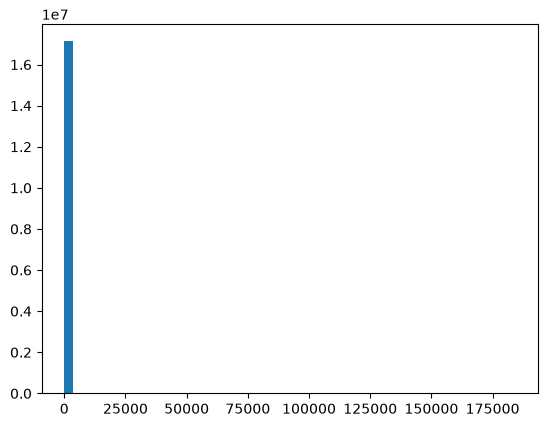

In [24]:
plt.hist(df["OUT_PKTS"], bins=50)


In [25]:
df.columns.tolist()

['L4_SRC_PORT',
 'L4_DST_PORT',
 'PROTOCOL',
 'L7_PROTO',
 'IN_BYTES',
 'IN_PKTS',
 'OUT_BYTES',
 'OUT_PKTS',
 'TCP_FLAGS',
 'CLIENT_TCP_FLAGS',
 'SERVER_TCP_FLAGS',
 'FLOW_DURATION_MILLISECONDS',
 'DURATION_IN',
 'DURATION_OUT',
 'MIN_TTL',
 'MAX_TTL',
 'LONGEST_FLOW_PKT',
 'SHORTEST_FLOW_PKT',
 'MIN_IP_PKT_LEN',
 'MAX_IP_PKT_LEN',
 'SRC_TO_DST_SECOND_BYTES',
 'DST_TO_SRC_SECOND_BYTES',
 'RETRANSMITTED_IN_BYTES',
 'RETRANSMITTED_IN_PKTS',
 'RETRANSMITTED_OUT_BYTES',
 'RETRANSMITTED_OUT_PKTS',
 'SRC_TO_DST_AVG_THROUGHPUT',
 'DST_TO_SRC_AVG_THROUGHPUT',
 'NUM_PKTS_UP_TO_128_BYTES',
 'NUM_PKTS_128_TO_256_BYTES',
 'NUM_PKTS_256_TO_512_BYTES',
 'NUM_PKTS_512_TO_1024_BYTES',
 'NUM_PKTS_1024_TO_1514_BYTES',
 'TCP_WIN_MAX_IN',
 'TCP_WIN_MAX_OUT',
 'ICMP_TYPE',
 'ICMP_IPV4_TYPE',
 'DNS_QUERY_ID',
 'DNS_QUERY_TYPE',
 'DNS_TTL_ANSWER',
 'FTP_COMMAND_RET_CODE',
 'Label',
 'Attack']

In [26]:

# ==========================================
# DATASET INSPECTION: NF-CSE-CIC-IDS2018-V2
# ==========================================

import pandas as pd
import numpy as np

# 1. Dataset size
print("=" * 60)
print("1. DATASET DIMENSIONS")
print("=" * 60)
print(f"Rows: {df.shape[0]:,}")
print(f"Columns: {df.shape[1]}")

# 2. Column names and data types
print("\n" + "=" * 60)
print("2. SCHEMA AND MEMORY")
print("=" * 60)
df.info()

# 3. Missing values
print("\n" + "=" * 60)
print("3. MISSING VALUES")
print("=" * 60)
missing = df.isna().sum()
print(missing[missing > 0] if missing.any() else "No missing values found.")

# 4. Infinite values in numeric columns
print("\n" + "=" * 60)
print("4. INFINITE VALUES")
print("=" * 60)
numeric_df = df.select_dtypes(include="number")
infinite = pd.Series(
    np.isinf(numeric_df).sum(),
    index=numeric_df.columns
)
print(infinite[infinite > 0] if infinite.any() else "No infinite values found.")

# 5. Exact duplicate rows
print("\n" + "=" * 60)
print("5. DUPLICATE ROWS")
print("=" * 60)
print(f"Exact duplicate rows: {df.duplicated().sum():,}")

# 6. Binary target distribution
print("\n" + "=" * 60)
print("6. BINARY LABEL DISTRIBUTION")
print("=" * 60)
print(df["Label"].value_counts(dropna=False))
print("\nPercentages:")
print((df["Label"].value_counts(normalize=True, dropna=False) * 100).round(3))

# 7. Attack categories
print("\n" + "=" * 60)
print("7. ATTACK CATEGORY DISTRIBUTION")
print("=" * 60)
print(f"Distinct categories: {df['Attack'].nunique(dropna=False)}")
print(df["Attack"].value_counts(dropna=False))
print("\nPercentages:")
print((df["Attack"].value_counts(normalize=True, dropna=False) * 100).round(4))

# 8. Check consistency between Label and Attack
print("\n" + "=" * 60)
print("8. LABEL CONSISTENCY")
print("=" * 60)
print(pd.crosstab(df["Attack"], df["Label"], dropna=False))

# 9. Numeric summary
print("\n" + "=" * 60)
print("9. NUMERIC FEATURE SUMMARY")
print("=" * 60)
print(numeric_df.describe().T.to_string())

# 10. Potentially suspicious values
print("\n" + "=" * 60)
print("10. BASIC RANGE CHECKS")
print("=" * 60)
for col in ["IN_BYTES", "OUT_BYTES", "IN_PKTS", "OUT_PKTS",
            "FLOW_DURATION_MILLISECONDS"]:
    if col in df.columns:
        print(
            f"{col}: min={df[col].min()}, "
            f"max={df[col].max()}, "
            f"zeros={(df[col] == 0).sum():,}, "
            f"negative={(df[col] < 0).sum():,}"
        )

# 11. Save a compact inspection report
print("\n" + "=" * 60)
print("11. INSPECTION COMPLETE")
print("=" * 60)
print("Use the output above to decide preprocessing steps.")


1. DATASET DIMENSIONS
Rows: 17,129,715
Columns: 43

2. SCHEMA AND MEMORY
<class 'pandas.DataFrame'>
RangeIndex: 17129715 entries, 0 to 17129714
Data columns (total 43 columns):
 #   Column                       Dtype  
---  ------                       -----  
 0   L4_SRC_PORT                  int32  
 1   L4_DST_PORT                  int32  
 2   PROTOCOL                     int8   
 3   L7_PROTO                     float32
 4   IN_BYTES                     int32  
 5   IN_PKTS                      int32  
 6   OUT_BYTES                    int32  
 7   OUT_PKTS                     int32  
 8   TCP_FLAGS                    int16  
 9   CLIENT_TCP_FLAGS             int16  
 10  SERVER_TCP_FLAGS             int16  
 11  FLOW_DURATION_MILLISECONDS   int32  
 12  DURATION_IN                  int32  
 13  DURATION_OUT                 int32  
 14  MIN_TTL                      int16  
 15  MAX_TTL                      int16  
 16  LONGEST_FLOW_PKT             int32  
 17  SHORTEST_FLOW_PKT   

/home/krix/Network-Packet-Anomaly-Detector/.venv/lib64/python3.14/site-packages/pandas/core/nanops.py:1028: RuntimeWarning: overflow encountered in square
  sqr = _ensure_numeric((avg - values) ** 2)


                                  count           mean           std   min       25%        50%         75%            max
L4_SRC_PORT                  17129715.0   5.294724e+04  1.152073e+04   0.0   50903.0    54591.0     59793.0   6.553500e+04
L4_DST_PORT                  17129715.0   1.094130e+03  3.297370e+03   0.0      53.0       80.0       445.0   6.553500e+04
PROTOCOL                     17129715.0   1.099481e+01  5.488639e+00   1.0       6.0        6.0        17.0   5.800000e+01
L7_PROTO                     17129715.0   1.124135e+01  2.690619e+01   0.0       0.0        0.0         7.0   2.480000e+02
IN_BYTES                     17129715.0   1.950476e+03  8.362588e+04  28.0      69.0      144.0      1464.0   1.652525e+08
IN_PKTS                      17129715.0   2.516168e+01  1.147684e+03   1.0       1.0        3.0         9.0   2.922690e+05
OUT_BYTES                    17129715.0   7.548850e+03  5.221193e+05   0.0     119.0      294.0      1873.0   2.756398e+08
OUT_PKTS        

In [27]:
# Finish dataset inspection

print("1. EXACT DUPLICATE ROWS")
print(df.duplicated().sum())

print("\n2. BINARY LABEL DISTRIBUTION")
print(df["Label"].value_counts(dropna=False))
print((df["Label"].value_counts(normalize=True) * 100).round(3))

print("\n3. ATTACK CATEGORY DISTRIBUTION")
print(df["Attack"].value_counts(dropna=False))
print("\nPercentages:")
print((df["Attack"].value_counts(normalize=True) * 100).round(4))

print("\n4. LABEL CONSISTENCY")
print(pd.crosstab(df["Attack"], df["Label"], dropna=False))

print("\n5. NUMERIC FEATURE SUMMARY")
print(df.select_dtypes(include="number").describe().T.to_string())

print("\n6. BASIC RANGE CHECKS")
for col in [
    "IN_BYTES", "OUT_BYTES", "IN_PKTS", "OUT_PKTS",
    "FLOW_DURATION_MILLISECONDS"
]:
    print(
        f"{col}: min={df[col].min()}, "
        f"max={df[col].max()}, "
        f"zeros={(df[col] == 0).sum():,}, "
        f"negative={(df[col] < 0).sum():,}"
    )

1. EXACT DUPLICATE ROWS
0

2. BINARY LABEL DISTRIBUTION
Label
0    15101685
1     2028030
Name: count, dtype: int64
Label
0    88.161
1    11.839
Name: proportion, dtype: float64

3. ATTACK CATEGORY DISTRIBUTION
Attack
Benign                      15101685
DDOS attack-HOIC             1066881
DoS attacks-Hulk              432648
DDoS attacks-LOIC-HTTP        207078
Infilteration                 115513
SSH-Bruteforce                 94979
Bot                            28033
DoS attacks-GoldenEye          27723
FTP-BruteForce                 25933
DoS attacks-SlowHTTPTest       14116
DoS attacks-Slowloris           9512
Brute Force -Web                2143
DDOS attack-LOIC-UDP            2112
Brute Force -XSS                 927
SQL Injection                    432
Name: count, dtype: int64

Percentages:
Attack
Benign                      88.1607
DDOS attack-HOIC             6.2282
DoS attacks-Hulk             2.5257
DDoS attacks-LOIC-HTTP       1.2089
Infilteration                0.6743

/home/krix/Network-Packet-Anomaly-Detector/.venv/lib64/python3.14/site-packages/pandas/core/nanops.py:1028: RuntimeWarning: overflow encountered in square
  sqr = _ensure_numeric((avg - values) ** 2)


                                  count           mean           std   min       25%        50%         75%            max
L4_SRC_PORT                  17129715.0   5.294724e+04  1.152073e+04   0.0   50903.0    54591.0     59793.0   6.553500e+04
L4_DST_PORT                  17129715.0   1.094130e+03  3.297370e+03   0.0      53.0       80.0       445.0   6.553500e+04
PROTOCOL                     17129715.0   1.099481e+01  5.488639e+00   1.0       6.0        6.0        17.0   5.800000e+01
L7_PROTO                     17129715.0   1.124135e+01  2.690619e+01   0.0       0.0        0.0         7.0   2.480000e+02
IN_BYTES                     17129715.0   1.950476e+03  8.362588e+04  28.0      69.0      144.0      1464.0   1.652525e+08
IN_PKTS                      17129715.0   2.516168e+01  1.147684e+03   1.0       1.0        3.0         9.0   2.922690e+05
OUT_BYTES                    17129715.0   7.548850e+03  5.221193e+05   0.0     119.0      294.0      1873.0   2.756398e+08
OUT_PKTS        

In [28]:
# Check numeric columns for extreme magnitudes
numeric_df = df.select_dtypes(include="number")

print("Largest absolute value in each numeric column:")
print(numeric_df.abs().max().sort_values(ascending=False).to_string())

Largest absolute value in each numeric column:
SRC_TO_DST_SECOND_BYTES        6.588022e+304
DST_TO_SRC_SECOND_BYTES         3.122086e+73
DST_TO_SRC_AVG_THROUGHPUT       4.294480e+09
SRC_TO_DST_AVG_THROUGHPUT       3.847489e+09
OUT_BYTES                       2.756398e+08
IN_BYTES                        1.652525e+08
FLOW_DURATION_MILLISECONDS      4.294967e+06
RETRANSMITTED_OUT_BYTES         3.656809e+06
IN_PKTS                         2.922690e+05
NUM_PKTS_UP_TO_128_BYTES        2.922690e+05
RETRANSMITTED_IN_BYTES          2.370320e+05
OUT_PKTS                        1.842180e+05
NUM_PKTS_1024_TO_1514_BYTES     1.836310e+05
DNS_TTL_ANSWER                  1.344730e+05
DURATION_IN                     1.067140e+05
L4_DST_PORT                     6.553500e+04
L4_SRC_PORT                     6.553500e+04
TCP_WIN_MAX_IN                  6.553500e+04
DNS_QUERY_ID                    6.553500e+04
TCP_WIN_MAX_OUT                 6.553500e+04
ICMP_TYPE                       6.528000e+04
LONGEST_

In [29]:
print("Attack categories:")
print(df["Attack"].value_counts())

print("\nLabel mapping:")
print(pd.crosstab(df["Attack"], df["Label"]))

print("\nExact duplicate rows:")
print(df.duplicated().sum())

Attack categories:
Attack
Benign                      15101685
DDOS attack-HOIC             1066881
DoS attacks-Hulk              432648
DDoS attacks-LOIC-HTTP        207078
Infilteration                 115513
SSH-Bruteforce                 94979
Bot                            28033
DoS attacks-GoldenEye          27723
FTP-BruteForce                 25933
DoS attacks-SlowHTTPTest       14116
DoS attacks-Slowloris           9512
Brute Force -Web                2143
DDOS attack-LOIC-UDP            2112
Brute Force -XSS                 927
SQL Injection                    432
Name: count, dtype: int64

Label mapping:
Label                            0        1
Attack                                     
Benign                    15101685        0
Bot                              0    28033
Brute Force -Web                 0     2143
Brute Force -XSS                 0      927
DDOS attack-HOIC                 0  1066881
DDOS attack-LOIC-UDP             0     2112
DDoS attacks-LOIC-HTTP   

## Dataset Reconnaissance Summary

### Dataset
- **Name:** NF-CSE-CIC-IDS2018-V2
- **Format:** Parquet
- **Dimensions:** 17,129,715 rows × 43 columns
- **Reported DataFrame memory usage:** Approximately 2.6 GB

### Initial Data Quality
- No missing values were detected.
- No infinite values were detected in numeric columns.
- The exact duplicate-row count is 0.
- Numerical summaries triggered an overflow warning due to extreme values in directional bytes-per-second features.

### Target Labels
- `Label = 0`: Benign traffic
- `Label = 1`: Attack traffic
- Cross-tabulation confirmed consistency between `Label` and `Attack`.
- There are 15 categories: benign traffic and 14 attack categories.
- Approximately 88.16% of records are benign and 11.84% are attacks.

### Initial Feature Concerns
- `SRC_TO_DST_SECOND_BYTES` and `DST_TO_SRC_SECOND_BYTES` contain extreme values that require investigation.
- `FTP_COMMAND_RET_CODE` is constant at zero and is not useful as a predictive feature in this dataset.
- `FLOW_DURATION_MILLISECONDS` is zero for a large proportion of records; its interpretation requires further investigation.

### Initial Modeling Plan
- Begin with binary classification using `Label` as the target.
- Preserve `Attack` for later attack-category classification.
- Exclude target columns from model inputs.
- Investigate suspicious features before preprocessing.
- Evaluate using precision, recall, F1-score, and a confusion matrix in addition to accuracy.

### Limitations
These are preliminary findings from dataset inspection. Suspicious values have not yet been fully explained, and no model has been trained.

In [30]:

# Inspect the two suspicious rate features

rate_cols = [
    "SRC_TO_DST_SECOND_BYTES",
    "DST_TO_SRC_SECOND_BYTES"
]

for col in rate_cols:
    print(f"\n{'=' * 60}")
    print(f"Feature: {col}")
    print(df[col].describe(percentiles=[0.90, 0.95, 0.99, 0.999]))

    print("\nLargest 10 values:")
    print(df[col].nlargest(10).to_list())

    print("\nZero values:", (df[col] == 0).sum())
    print("Negative values:", (df[col] < 0).sum())
    print("NaN values:", df[col].isna().sum())



Feature: SRC_TO_DST_SECOND_BYTES


/home/krix/Network-Packet-Anomaly-Detector/.venv/lib64/python3.14/site-packages/pandas/core/nanops.py:1028: RuntimeWarning: overflow encountered in square
  sqr = _ensure_numeric((avg - values) ** 2)


count     1.712972e+07
mean     3.849396e+297
std                inf
min       0.000000e+00
90%       1.973000e+03
95%       2.789000e+03
99%       1.112170e+05
99.9%     2.529788e+08
max      6.588022e+304
Name: SRC_TO_DST_SECOND_BYTES, dtype: float64

Largest 10 values:
[6.58802154063901e+304, 5.754037860253813e+301, 1.3080191340143478e+300, 3.2520566403048064e+294, 1.9194010314099808e+291, 3.4320196804872074e+290, 1.4508012732012852e+287, 1.249801548601781e+287, 1.1808011622016264e+287, 1.15800115020191e+287]

Zero values: 1978
Negative values: 0
NaN values: 0

Feature: DST_TO_SRC_SECOND_BYTES
count    1.712972e+07
mean     1.822614e+66
std      7.543446e+69
min      0.000000e+00
90%      4.760000e+03
95%      6.740000e+03
99%      5.210950e+05
99.9%    6.092009e+07
max      3.122086e+73
Name: DST_TO_SRC_SECOND_BYTES, dtype: float64

Largest 10 values:
[3.122085841488128e+73, 3.1210410410467213e+53, 6.104813412255806e+46, 5.252133163222881e+39, 5.221535765765765e+39, 2.0841610410448

In [31]:

# Quantify the extreme tails of both features

for col in rate_cols:
    s = df[col]

    print(f"\n{'=' * 60}")
    print(col)

    for threshold in [1e6, 1e9, 1e12, 1e20, 1e100]:
        count = (s > threshold).sum()
        print(
            f"> {threshold:.0e}: "
            f"{count:,} rows "
            f"({count / len(df) * 100:.6f}%)"
        )



SRC_TO_DST_SECOND_BYTES
> 1e+06: 126,253 rows (0.737041%)
> 1e+09: 13,830 rows (0.080737%)
> 1e+12: 2,581 rows (0.015067%)
> 1e+20: 230 rows (0.001343%)
> 1e+100: 192 rows (0.001121%)

DST_TO_SRC_SECOND_BYTES
> 1e+06: 141,993 rows (0.828928%)
> 1e+09: 14,013 rows (0.081805%)
> 1e+12: 8,257 rows (0.048203%)
> 1e+20: 29 rows (0.000169%)
> 1e+100: 0 rows (0.000000%)


In [32]:

# Inspect records with the most extreme rate values

rate_cols = [
    "SRC_TO_DST_SECOND_BYTES",
    "DST_TO_SRC_SECOND_BYTES"
]

context_cols = [
    "FLOW_DURATION_MILLISECONDS",
    "DURATION_IN",
    "DURATION_OUT",
    "IN_BYTES",
    "OUT_BYTES",
    "IN_PKTS",
    "OUT_PKTS",
    "Label",
    "Attack"
]

# Collect the indices of the 10 largest values in each rate feature.
extreme_indices = set()

for col in rate_cols:
    extreme_indices.update(
        df[col].nlargest(10).index.tolist()
    )

# Display the records, including both rate features.
cols_to_show = rate_cols + context_cols

extreme_rows = df.loc[
    sorted(extreme_indices), cols_to_show
]

with __import__("pandas").option_context(
    "display.max_columns", None,
    "display.width", 200
):
    display(extreme_rows)


,SRC_TO_DST_SECOND_BYTES,DST_TO_SRC_SECOND_BYTES,FLOW_DURATION_MILLISECONDS,DURATION_IN,DURATION_OUT,IN_BYTES,OUT_BYTES,IN_PKTS,OUT_PKTS,Label,Attack
487481,2.885761e+32,2.084161e+36,4284004,10963,10920,4160,7440,64,62,0,Benign
663965,3.921841e+55,3.121041e+53,4263207,31759,31673,5016,5400,69,43,0,Benign
4287106,3.922483e+65,3.122086e+73,4247705,47261,47218,7592,19304,125,147,0,Benign
5556358,1.308019e+300,0.000000e+00,4237289,57678,0,3827760,0,63796,0,1,DDOS attack-LOIC-UDP
5709103,1.594214e+33,1.344476e+30,4288902,6065,6065,106612,60724,321,277,0,Benign
6699363,5.754038e+301,0.000000e+00,4235591,59375,0,2802180,0,46703,0,1,DDOS attack-LOIC-UDP
6739731,3.252057e+294,0.000000e+00,4237075,57891,0,2404740,0,40079,0,1,DDOS attack-LOIC-UDP
7414892,4.909708e+28,6.104813e+46,4289791,5176,5176,69681,27681971,1574,18662,0,Benign
10217082,3.432020e+290,0.000000e+00,4237821,57145,0,2579280,0,42988,0,1,DDOS attack-LOIC-UDP
10634516,1.158001e+287,0.000000e+00,4248159,46807,0,11556600,0,192610,0,1,DDOS attack-LOIC-UDP


In [33]:

# Inspect the dataset's supplied feature documentation

feature_docs = pd.read_csv(
    "../data/raw/NetFlow v2 Features.csv"
)

print("Documentation shape:", feature_docs.shape)
print("Columns:", feature_docs.columns.tolist())

display(feature_docs.head(10))

# Search for definitions related to the suspicious features.
for col in [
    "SRC_TO_DST_SECOND_BYTES",
    "DST_TO_SRC_SECOND_BYTES",
    "IN_BYTES",
    "OUT_BYTES",
    "FLOW_DURATION_MILLISECONDS"
]:
    print(f"\n--- {col} ---")

    matches = feature_docs.astype(str).apply(
        lambda column: column.str.contains(
            col, case=False, regex=False, na=False
        )
    ).any(axis=1)

    display(feature_docs.loc[matches])


Documentation shape: (43, 2)
Columns: ['Feature', 'Description']


,Feature,Description
0,IPV4_SRC_ADDR,IPv4 source address
1,IPV4_DST_ADDR,IPv4 destination address
2,L4_SRC_PORT,IPv4 source port number
3,L4_DST_PORT,IPv4 destination port number
4,PROTOCOL,IP protocol identifier byte
5,L7_PROTO,Layer 7 protocol (numeric)
6,IN_BYTES,Incoming number of bytes
7,OUT_BYTES,Outgoing number of bytes
8,IN_PKTS,Incoming number of packets
9,OUT_PKTS,Outgoing number of packets



--- SRC_TO_DST_SECOND_BYTES ---


,Feature,Description
22,SRC_TO_DST_SECOND_BYTES,Src to dst Bytes/sec



--- DST_TO_SRC_SECOND_BYTES ---


...

,Feature,Description
6,IN_BYTES,Incoming number of bytes
24,RETRANSMITTED_IN_BYTES,Number of retransmitted TCP flow bytes (src->dst)



--- OUT_BYTES ---


,Feature,Description
7,OUT_BYTES,Outgoing number of bytes
26,RETRANSMITTED_OUT_BYTES,Number of retransmitted TCP flow bytes (dst->src)



--- FLOW_DURATION_MILLISECONDS ---


,Feature,Description
10,FLOW_DURATION_MILLISECONDS,Flow duration in milliseconds


In [34]:

# Check whether extreme rate values coincide with zero durations

rate_cols = [
    "SRC_TO_DST_SECOND_BYTES",
    "DST_TO_SRC_SECOND_BYTES"
]

duration_cols = [
    "FLOW_DURATION_MILLISECONDS",
    "DURATION_IN",
    "DURATION_OUT"
]

for rate_col in rate_cols:
    print(f"\n{'=' * 60}")
    print("Rate feature:", rate_col)

    extreme = df[rate_col] > 1e12

    print("Rows above 1e12:", int(extreme.sum()))

    for duration_col in duration_cols:
        zero_duration = df[duration_col] == 0

        print(
            f"{duration_col} == 0 among extreme rows:",
            int((extreme & zero_duration).sum())
        )

        print(
            f"{duration_col} == 0 among all rows:",
            int(zero_duration.sum())
        )



Rate feature: SRC_TO_DST_SECOND_BYTES
Rows above 1e12: 2581
FLOW_DURATION_MILLISECONDS == 0 among extreme rows: 0
FLOW_DURATION_MILLISECONDS == 0 among all rows: 14707208
DURATION_IN == 0 among extreme rows: 0
DURATION_IN == 0 among all rows: 14807171
DURATION_OUT == 0 among extreme rows: 327
DURATION_OUT == 0 among all rows: 14911619

Rate feature: DST_TO_SRC_SECOND_BYTES
Rows above 1e12: 8257
FLOW_DURATION_MILLISECONDS == 0 among extreme rows: 0
FLOW_DURATION_MILLISECONDS == 0 among all rows: 14707208
DURATION_IN == 0 among extreme rows: 2
DURATION_IN == 0 among all rows: 14807171
DURATION_OUT == 0 among extreme rows: 0
DURATION_OUT == 0 among all rows: 14911619


In [35]:

# Compare observed rates with candidate byte-count / duration ratios.
# This is a diagnostic only; the directional mapping and duration units
# have not yet been verified.

extreme_mask = (
    (df["SRC_TO_DST_SECOND_BYTES"] > 1e12)
    | (df["DST_TO_SRC_SECOND_BYTES"] > 1e12)
)

check_cols = [
    "SRC_TO_DST_SECOND_BYTES",
    "DST_TO_SRC_SECOND_BYTES",
    "IN_BYTES",
    "OUT_BYTES",
    "DURATION_IN",
    "DURATION_OUT",
    "FLOW_DURATION_MILLISECONDS",
    "Label",
    "Attack"
]

sample = df.loc[extreme_mask, check_cols].head(15).copy()

# Candidate rates using the directional duration fields.
# Replace zero denominators with NaN to avoid division by zero.
sample["IN_BYTES_per_DURATION_IN"] = (
    sample["IN_BYTES"] /
    sample["DURATION_IN"].replace(0, float("nan"))
)

sample["OUT_BYTES_per_DURATION_OUT"] = (
    sample["OUT_BYTES"] /
    sample["DURATION_OUT"].replace(0, float("nan"))
)

display(sample)


,SRC_TO_DST_SECOND_BYTES,DST_TO_SRC_SECOND_BYTES,IN_BYTES,OUT_BYTES,DURATION_IN,DURATION_OUT,FLOW_DURATION_MILLISECONDS,Label,Attack,IN_BYTES_per_DURATION_IN,OUT_BYTES_per_DURATION_OUT
87,3.200633e+12,3.869763e+12,21940,26823,1984,1984,4292983,1,SSH-Bruteforce,11.058468,13.519657
2120,3.220631e+12,3.765769e+12,22200,26615,1969,1969,4292998,1,SSH-Bruteforce,11.274759,13.517014
8160,9.444940e+11,1.150311e+13,21956,26615,1906,1906,4293061,1,SSH-Bruteforce,11.519412,13.963799
9307,3.116638e+12,3.869774e+12,22044,26927,1984,1984,4292983,1,SSH-Bruteforce,11.110887,13.572077
9444,3.268625e+12,3.869763e+12,22200,26875,1984,1984,4292983,1,SSH-Bruteforce,11.189516,13.545867
13256,9.548938e+11,1.150312e+13,22076,26875,1921,1921,4293046,1,SSH-Bruteforce,11.491931,13.990109
13359,9.376957e+11,1.139911e+13,22080,26459,1891,1891,4293076,1,SSH-Bruteforce,11.676362,13.992068
14763,9.652936e+11,1.139912e+13,22144,26771,1875,1875,4293092,1,SSH-Bruteforce,11.810133,14.277867
21160,9.480952e+11,1.150312e+13,22220,26771,1890,1890,4293077,1,SSH-Bruteforce,11.756614,14.164550
22090,1.146865e+11,6.868590e+14,571764,39225667,47,78,4294889,0,Benign,12165.191489,502893.166667


In [36]:

# Investigate duration values and the constant feature

duration_col = "FLOW_DURATION_MILLISECONDS"

print("Duration unique values:", df[duration_col].nunique())
print("Duration minimum:", df[duration_col].min())
print("Duration maximum:", df[duration_col].max())

print("\nMost frequent duration values:")
display(df[duration_col].value_counts().head(15))

print("\nLargest 15 duration values:")
display(
    df[duration_col]
    .nlargest(15)
    .value_counts()
    .sort_index(ascending=False)
)

print("\nFTP_COMMAND_RET_CODE:")
print("Unique values:", df["FTP_COMMAND_RET_CODE"].nunique())
print(df["FTP_COMMAND_RET_CODE"].value_counts().head())



Duration unique values: 4493
Duration minimum: 0
Duration maximum: 4294967

Most frequent duration values:


FLOW_DURATION_MILLISECONDS
0          14707208
4294951      378031
4294952      234209
4294964      108205
4294963      105051
4294936       72016
4294670       50792
4294920       49218
4294962       48207
4294686       45523
4294717       41618
4294935       39904
4294795       38247
4294701       32581
4294961       32537
Name: count, dtype: int64


Largest 15 duration values:


FLOW_DURATION_MILLISECONDS
4294967    15
Name: count, dtype: int64


FTP_COMMAND_RET_CODE:
Unique values: 1
FTP_COMMAND_RET_CODE
0    17129715
Name: count, dtype: int64


# Phase 2: Feature Semantics and Data Validation

## 1. Objective

The objective of this phase was to understand the meaning and quality of the dataset's features, investigate suspicious values, and decide which features should be retained, investigated further, or excluded from the first baseline model.

The goal was not to clean the data blindly, but to make evidence-based and reproducible feature-selection decisions.

## 2. Feature Documentation

The supplied `NetFlow v2 Features.csv` file contains 43 feature definitions.

We inspected the descriptions of important fields, including:

- `IN_BYTES`: Incoming number of bytes.
- `OUT_BYTES`: Outgoing number of bytes.
- `FLOW_DURATION_MILLISECONDS`: Flow duration in milliseconds.
- `SRC_TO_DST_SECOND_BYTES`: Source-to-destination bytes per second.
- `DST_TO_SRC_SECOND_BYTES`: Destination-to-source bytes per second.

The documentation established the basic meaning of these features but did not specify the calculation formulas for the two directional rate features.

**Conclusion:** Feature names and descriptions provide useful context, but they are not always sufficient to establish how a value was calculated.

## 3. Investigation of Extreme Rate Features

The following features were identified for further investigation:

- `SRC_TO_DST_SECOND_BYTES`
- `DST_TO_SRC_SECOND_BYTES`

We used `describe()`, high percentiles, `nlargest()`, and threshold counts to examine their distributions.

### Results

| Measurement | `SRC_TO_DST_SECOND_BYTES` | `DST_TO_SRC_SECOND_BYTES` |
|---|---:|---:|
| 99th percentile | 111,217 | 521,095 |
| Maximum | Approximately \(6.59 \times 10^{304}\) | Approximately \(3.12 \times 10^{73}\) |
| Values above \(10^{12}\) | 2,581 | 8,257 |
| Values above \(10^{20}\) | 230 | 29 |

The first feature also produced an infinite standard deviation during summary-statistic calculation because of the scale of its extreme values.

These results show that the extreme values are far beyond the ordinary upper percentiles. However, an extreme value alone does not prove that a record is invalid.

### Additional investigation

We inspected the records with the largest rate values alongside byte counts, packet counts, duration fields, labels, and attack categories.

Some extreme records belonged to `DDOS attack-LOIC-UDP` and had zero inbound bytes and packets despite substantial outbound traffic. Other extreme records belonged to benign traffic.

We also checked whether extreme values coincided with zero durations.

| Diagnostic | Source-to-destination rate | Destination-to-source rate |
|---|---:|---:|
| Records above \(10^{12}\) | 2,581 | 8,257 |
| Zero flow duration | 0 | 0 |
| Zero `DURATION_IN` | 0 | 2 |
| Zero `DURATION_OUT` | 327 | 0 |

Zero durations therefore do not explain the overall extreme-rate problem.

Candidate byte-count-to-duration ratios were also calculated for selected records. They did not explain the observed rate values under the simple ratios examined.

### Decision

Both rate features will be **provisionally excluded from the first baseline model** because their extreme values and calculation behavior remain unexplained.

Their root cause has not been established. They may be reconsidered if further documentation or analysis establishes a reliable interpretation or handling strategy.

## 4. Investigation of Flow Duration

We inspected `FLOW_DURATION_MILLISECONDS` using its minimum, maximum, number of unique values, and most frequent values.

### Results

- Total records: 17,129,715.
- Records with zero duration: 14,707,208.
- Number of unique duration values: 4,493.
- Maximum duration: 4,294,967 milliseconds.
- Many frequent nonzero values are close to the observed maximum.

The maximum is close to a possible 32-bit timer boundary expressed in milliseconds. This is a hypothesis worth investigating, not a confirmed explanation.

The high number of zero-duration records also requires interpretation using the dataset's flow-generation methodology.

### Decision

`FLOW_DURATION_MILLISECONDS` will be **retained provisionally**. We will not delete zero-duration records or transform the feature without further evidence.

## 5. Investigation of the Constant Feature

We checked the number of unique values and value counts for `FTP_COMMAND_RET_CODE`.

The feature has exactly one unique value: `0`, across all 17,129,715 records.

A constant feature has no variation and cannot discriminate between benign and malicious records in this dataset.

### Decision

`FTP_COMMAND_RET_CODE` will be **excluded from the first baseline model's feature set** because it contains no predictive variation in the observed data.

The original column will remain in the raw dataset.

## 6. Feature-Handling Decisions

| Feature | Evidence | Decision |
|---|---|---|
| `SRC_TO_DST_SECOND_BYTES` | Extreme finite values; calculation unexplained | Provisionally exclude from baseline |
| `DST_TO_SRC_SECOND_BYTES` | Extreme finite values; calculation unexplained | Provisionally exclude from baseline |
| `FTP_COMMAND_RET_CODE` | Constant value of zero | Exclude from baseline |
| `FLOW_DURATION_MILLISECONDS` | Many zeros and values near a possible upper boundary | Retain; investigate further |
| Other features | No exclusion decision established in this phase | Retain as candidates pending preprocessing and leakage checks |

These decisions are based on feature validity and information content, not on demonstrated improvements in model accuracy. No model has been trained yet.

## 7. Raw Data Preservation and Reproducibility

The raw dataset will remain unchanged.

Feature exclusions will be applied in the preprocessing or feature-selection pipeline rather than by deleting columns from the original file.

This preserves the ability to reproduce the investigation, revisit decisions, and compare future experiments.

## 8. Outstanding Questions

The following issues remain unresolved:

1. What formulas generate the two directional rate features?
2. Why are zero-duration records so common?
3. What explains the cluster of duration values near the observed maximum?
4. Can additional dataset documentation clarify these behaviors?

These questions should remain documented and can be revisited when further evidence becomes available.

## 9. Phase 2 Outcome

Phase 2 established a preliminary feature-handling plan for the first binary classification baseline.

The investigation identified two rate features requiring further verification, one constant feature that provides no variation, and a duration feature that should be retained pending additional analysis.

The next phase will define the model inputs and target, establish a leakage-resistant train/validation/test split, and design the preprocessing pipeline.

# Phase 3 : Pre processing and data splitting

In [38]:

#Checking 4 available split metadata

print("Dataset shape:", df.shape)

print("\nPotential time or grouping columns:")
terms = ["time", "date", "capture", "session", "flow_id"]

matches = [
    col for col in df.columns
    if any(term in col.lower() for term in terms)
]

print(matches if matches else "No obvious metadata columns found.")

print("\nTarget distribution:")
print(df["Label"].value_counts(normalize=True).sort_index())


Dataset shape: (17129715, 43)

Potential time or grouping columns:
No obvious metadata columns found.

Target distribution:
Label
0    0.881607
1    0.118393
Name: proportion, dtype: float64


In [39]:
#Separatin features and target

excluded_cols = [
    "Label",
    "Attack",
    "SRC_TO_DST_SECOND_BYTES",
    "DST_TO_SRC_SECOND_BYTES",
    "FTP_COMMAND_RET_CODE"
]

X = df.drop(columns=excluded_cols)
y = df["Label"]

print("Feature matrix shape:", X.shape)
print("Target shape:", y.shape)

print("\nTarget distribution:")
print(y.value_counts(normalize=True).sort_index())

print("\nRemaining feature columns:")
print(X.columns.tolist())


Feature matrix shape: (17129715, 38)
Target shape: (17129715,)

Target distribution:
Label
0    0.881607
1    0.118393
Name: proportion, dtype: float64

Remaining feature columns:
['L4_SRC_PORT', 'L4_DST_PORT', 'PROTOCOL', 'L7_PROTO', 'IN_BYTES', 'IN_PKTS', 'OUT_BYTES', 'OUT_PKTS', 'TCP_FLAGS', 'CLIENT_TCP_FLAGS', 'SERVER_TCP_FLAGS', 'FLOW_DURATION_MILLISECONDS', 'DURATION_IN', 'DURATION_OUT', 'MIN_TTL', 'MAX_TTL', 'LONGEST_FLOW_PKT', 'SHORTEST_FLOW_PKT', 'MIN_IP_PKT_LEN', 'MAX_IP_PKT_LEN', 'RETRANSMITTED_IN_BYTES', 'RETRANSMITTED_IN_PKTS', 'RETRANSMITTED_OUT_BYTES', 'RETRANSMITTED_OUT_PKTS', 'SRC_TO_DST_AVG_THROUGHPUT', 'DST_TO_SRC_AVG_THROUGHPUT', 'NUM_PKTS_UP_TO_128_BYTES', 'NUM_PKTS_128_TO_256_BYTES', 'NUM_PKTS_256_TO_512_BYTES', 'NUM_PKTS_512_TO_1024_BYTES', 'NUM_PKTS_1024_TO_1514_BYTES', 'TCP_WIN_MAX_IN', 'TCP_WIN_MAX_OUT', 'ICMP_TYPE', 'ICMP_IPV4_TYPE', 'DNS_QUERY_ID', 'DNS_QUERY_TYPE', 'DNS_TTL_ANSWER']


In [40]:
from sklearn.model_selection import train_test_split

In [42]:
#reserving 15% for final test set

train_val_idx,test_idx = train_test_split(
    X.index,
    test_size = 0.15,
    random_state = 42,
    stratify = y
)

#reserving 15% of the full dataset for validation
# 15/85 = 0.17647, so this gives a 70/15/15 overall split.
train_idx, val_idx = train_test_split(
    train_val_idx,
    test_size = 0.1764705882,
    random_state = 42,
    stratify = y.loc[train_val_idx]
)

print("Training rows:", len(train_idx))
print("Validation rows:", len(val_idx))
print("Test rows:", len(test_idx))


Training rows: 11990799
Validation rows: 2569458
Test rows: 2569458


In [44]:

# Verify sizes and class proportions

for name, idx in [
    ("Train", train_idx),
    ("Validation", val_idx),
    ("Test", test_idx)
]:
    print(f"\n{name}")
    print("Rows:", len(idx))
    print("Class proportions:")
    print(y.loc[idx].value_counts(normalize=True).sort_index())

# Verify that no row indices overlap.
assert len(set(train_idx) & set(val_idx)) == 0
assert len(set(train_idx) & set(test_idx)) == 0
assert len(set(val_idx) & set(test_idx)) == 0

print("\nAll three index sets are disjoint.")


Train
Rows: 11990799
Class proportions:
Label
0    0.881608
1    0.118392
Name: proportion, dtype: float64

Validation
Rows: 2569458
Class proportions:
Label
0    0.881607
1    0.118393
Name: proportion, dtype: float64

Test
Rows: 2569458
Class proportions:
Label
0    0.881607
1    0.118393
Name: proportion, dtype: float64

All three index sets are disjoint.
